# Cyclistic — Data Preparation and Analysis

**Objective:** Compare casual riders and annual members to identify evidence-based opportunities to convert casual riders into members.

**Period:** October 1, 2025–September 30, 2026.  
**Source:** [Official Divvy trip-data archive](https://divvy-tripdata.s3.amazonaws.com/index.html)

This improved notebook changes the input workflow to download monthly source archives directly, while retaining the existing cleaning rules and key analyses. It is a reconstructed improved version, not a byte-for-byte copy of every cell in the original notebook.

## 1. Imports and paths

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "https://divvy-tripdata.s3.amazonaws.com/"
START_DATE = pd.Timestamp("2025-10-01")
END_DATE = pd.Timestamp("2026-10-01")  # Exclusive

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Download and combine the monthly source files

This expects each archive to be named `YYYYMM-divvy-tripdata.zip`. It stops if a download fails or the archive does not contain exactly one CSV.

In [3]:
months = pd.period_range("2025-10", "2026-09", freq="M")
monthly_data = []

for month in months:
    filename = f"{month.strftime('%Y%m')}-divvy-tripdata.zip"
    url = BASE_URL + filename
    print(f"Downloading {filename}...")

    with urlopen(url, timeout=120) as response:
        zip_bytes = response.read()

    with ZipFile(BytesIO(zip_bytes)) as archive:
        csv_files = [
            n for n in archive.namelist()
            if n.lower().endswith(".csv")
            and not n.startswith("__MACOSX/")
            and not Path(n).name.startswith("._")
        ]
        if len(csv_files) != 1:
            raise ValueError(f"Expected one CSV in {filename}; found {csv_files}")
        with archive.open(csv_files[0]) as csv_file:
            monthly_df = pd.read_csv(csv_file)

    monthly_data.append(monthly_df)
    print(f"  Rows loaded: {len(monthly_df):,}")

data_original = pd.concat(monthly_data, ignore_index=True)
print("Combined shape:", data_original.shape)
print("Columns:", data_original.columns.tolist())

  Rows loaded: 646,039
  Rows loaded: 356,628
  Rows loaded: 140,534
  Rows loaded: 137,787
  Rows loaded: 201,450
  Rows loaded: 317,037
  Rows loaded: 448,252
  Rows loaded: 653,704
  Rows loaded: 762,550
  Rows loaded: 869,051
  Rows loaded: 868,191
  Rows loaded: 770,562
Combined shape: (6171785, 13)
Columns: ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


## 3. Save combined source data

In [4]:
combined_path = DATA_DIR / "cyclistic_combined.csv"
data_original.to_csv(combined_path, index=False)
print(f"Saved combined data to: {combined_path}")

Saved combined data to: /Users/Marcin_1/Desktop/Portfolio_projects/Ciclistic/2026/data/cyclistic_combined.csv


## 4. Initial inspection

In [5]:
print("Shape:", data_original.shape)
display(data_original.head())
data_original.info()

missing_summary = data_original.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(data_original) * 100).round(2)
display(missing_summary)

print("Rider categories:")
display(data_original["member_casual"].value_counts(dropna=False))
print("Bike categories:")
display(data_original["rideable_type"].value_counts(dropna=False))
print("Duplicate ride IDs before cleaning:", data_original["ride_id"].duplicated().sum())

Shape: (6171785, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,41.883180,-87.635110,member
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,41.892592,-87.617289,member
2,90429D9729A3EE8E,classic_bike,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,Clinton St & 18th St,CHI00235,Desplaines St & Jackson Blvd,CHI00518,41.857950,-87.640826,41.878119,-87.643948,casual
3,C8433F9B78A1E63D,electric_bike,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,Pine Grove Ave & Irving Park Rd,CHI00482,Wells St & Huron St,CHI00294,41.954398,-87.647997,41.894795,-87.634374,member
4,62F3C413C442C154,electric_bike,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,Pine Grove Ave & Irving Park Rd,CHI00482,Sheridan Rd & Montrose Ave,CHI00290,41.954365,-87.647929,41.961670,-87.654640,member


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6171785 entries, 0 to 6171784
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 612.1+ MB


,missing_count,missing_percent
end_station_name,1355487,21.96
end_station_id,1355487,21.96
start_station_name,1289486,20.89
start_station_id,1289486,20.89
end_lat,5451,0.09
end_lng,5451,0.09
ride_id,0,0.00
rideable_type,0,0.00
started_at,0,0.00
ended_at,0,0.00


Rider categories:


member_casual
member    3982761
casual    2189024
Name: count, dtype: int64

Bike categories:


rideable_type
electric_bike    4387353
classic_bike     1784432
Name: count, dtype: int64

Duplicate ride IDs before cleaning: 35


## 5. Parse timestamps and filter the target period

Filter first so cleaning counts describe the selected year.

In [6]:
data = data_original.copy()
for column in ["started_at", "ended_at"]:
    data[column] = pd.to_datetime(data[column], errors="coerce")

rows_before_filter = len(data)
data = data.loc[
    (data["started_at"] >= START_DATE) &
    (data["started_at"] < END_DATE)
].copy()

print("Rows before date filter:", f"{rows_before_filter:,}")
print("Rows in target period:", f"{len(data):,}")
print("First ride:", data["started_at"].min())
print("Last ride:", data["started_at"].max())
print("Missing started_at:", data["started_at"].isna().sum())
print("Missing ended_at:", data["ended_at"].isna().sum())

Rows before date filter: 6,171,785
Rows in target period: 6,171,714
First ride: 2025-10-01 00:00:12.789000
Last ride: 2026-09-30 23:59:38.090000
Missing started_at: 0
Missing ended_at: 0


## 6. Remove exact duplicates and inspect duplicate IDs

Remove identical rows, then investigate any repeated IDs that remain. Do not automatically delete non-identical records sharing an ID.

In [7]:
rows_before = len(data)
data = data.drop_duplicates().copy()
print("Exact duplicate rows removed:", f"{rows_before - len(data):,}")
print("Rows after exact deduplication:", f"{len(data):,}")

duplicate_ids = data.loc[data["ride_id"].duplicated(keep=False)].sort_values("ride_id")
print("Rows with repeated ride IDs:", len(duplicate_ids))
display(duplicate_ids.head(20))

Exact duplicate rows removed: 35
Rows after exact deduplication: 6,171,679
Rows with repeated ride IDs: 0


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual


## 7. Duration checks and cleaning

Project rules: exclude missing timestamps, negative durations, rides shorter than one minute, and rides longer than 24 hours. Retain exactly 24-hour rides. Pre-cleaning quality counts can overlap.

In [8]:
data["ride_duration_seconds"] = (data["ended_at"] - data["started_at"]).dt.total_seconds()
data["ride_duration_minutes"] = data["ride_duration_seconds"] / 60
data["ride_duration_hours"] = data["ride_duration_seconds"] / 3600

quality_counts = {
    "Missing start or end timestamp": (data["started_at"].isna() | data["ended_at"].isna()).sum(),
    "Negative durations": (data["ride_duration_seconds"] < 0).sum(),
    "Zero durations": (data["ride_duration_seconds"] == 0).sum(),
    "Durations under 1 minute": (data["ride_duration_seconds"] < 60).sum(),
    "Durations over 24 hours": (data["ride_duration_hours"] > 24).sum(),
}
for issue, count in quality_counts.items():
    print(f"{issue}: {count:,}")

# Optional investigation; this threshold is 10 hours.
long_rides = data.loc[data["ride_duration_hours"] > 10]
print("Rides longer than 10 hours:", f"{len(long_rides):,}")
display(long_rides.head(10))

Missing start or end timestamp: 0
Negative durations: 29
Zero durations: 0
Durations under 1 minute: 159,221
Durations over 24 hours: 5,304
Rides longer than 10 hours: 7,935


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_seconds,ride_duration_minutes,ride_duration_hours
871,FC1EDF5034D74691,classic_bike,2025-10-13 17:23:47.825,2025-10-14 18:23:26.635,Clark St & Eddy St,CHI02122,NaN,NaN,41.946280,-87.656270,NaN,NaN,casual,89978.810,1499.646833,24.994114
969,0CBA22FC04DE534B,classic_bike,2025-10-12 17:18:32.118,2025-10-13 18:18:10.655,Stockton Dr & Wrightwood Ave,CHI00522,NaN,NaN,41.931320,-87.638742,NaN,NaN,casual,89978.537,1499.642283,24.994038
2374,001CD0362DD48C22,classic_bike,2025-10-19 14:38:42.130,2025-10-20 08:11:36.696,Shedd Aquarium,CHI00533,Dusable Harbor,CHI00531,41.867226,-87.615355,41.886976,-87.612813,casual,63174.566,1052.909433,17.548491
3203,76333806FEF6A21B,classic_bike,2025-10-12 07:19:16.937,2025-10-13 07:02:58.439,Wabash Ave & Grand Ave,CHI00313,Clinton St & Tilden St,CHI01542,41.891466,-87.626761,41.875885,-87.640795,casual,85421.502,1423.691700,23.728195
4941,D6DD3DC7DD4D40DF,classic_bike,2025-10-18 16:32:47.052,2025-10-19 11:30:49.384,Michigan Ave & Oak St,CHI00252,Stetson Ave & South Water St,CHI00432,41.900960,-87.623777,41.886835,-87.622320,casual,68282.332,1138.038867,18.967314
9354,5A665293367B0638,classic_bike,2025-10-10 15:53:21.470,2025-10-11 12:19:26.670,California Ave & Touhy Ave,CHI01834,Glenwood Ave & Touhy Ave,CHI01143,42.012037,-87.700437,42.012701,-87.666058,member,73565.200,1226.086667,20.434778
10080,A6259386B728187F,classic_bike,2025-10-29 17:17:45.699,2025-10-30 10:59:30.186,Stave St & Armitage Ave,CHI00412,California Ave & Francis Pl,CHI00512,41.917741,-87.691392,41.918491,-87.697423,member,63704.487,1061.741450,17.695691
10256,4F8D3AA7C4937E67,classic_bike,2025-10-29 14:57:27.248,2025-10-30 10:59:30.186,Milwaukee Ave & Rockwell St,CHI00289,California Ave & Francis Pl,CHI00512,41.920330,-87.693090,41.918491,-87.697423,casual,72122.938,1202.048967,20.034149
11132,4D99BED5377AC8FB,classic_bike,2025-10-15 21:38:30.419,2025-10-16 08:58:02.983,State St & Randolph St,CHI00251,State St & Kinzie St,CHI00288,41.884621,-87.627834,41.889375,-87.627077,member,40772.564,679.542733,11.325712
12550,27513C4E9109E411,classic_bike,2025-10-18 17:09:53.547,2025-10-19 18:09:48.267,Sheridan Rd & Loyola Ave,CHI00752,NaN,NaN,42.001044,-87.661198,NaN,NaN,casual,89994.720,1499.912000,24.998533


In [9]:
rows_before_cleaning = len(data)
data = data.dropna(subset=["started_at", "ended_at"]).copy()
data = data.loc[data["ride_duration_seconds"] >= 0].copy()
data = data.loc[data["ride_duration_seconds"] >= 60].copy()
data = data.loc[data["ride_duration_hours"] <= 24].copy()

print("Rows before duration cleaning:", f"{rows_before_cleaning:,}")
print("Rows after duration cleaning:", f"{len(data):,}")
print("Rows removed:", f"{rows_before_cleaning - len(data):,}")

Rows before duration cleaning: 6,171,679
Rows after duration cleaning: 6,007,154
Rows removed: 164,525


## 8. Check categories and missing station information

In [10]:
print("Missing ride IDs:", data["ride_id"].isna().sum())
print("Missing rider categories:", data["member_casual"].isna().sum())
print("Missing bike categories:", data["rideable_type"].isna().sum())
display(data["member_casual"].value_counts(dropna=False))
display(data["rideable_type"].value_counts(dropna=False))

station_columns = [
    "start_station_name", "start_station_id", "end_station_name", "end_station_id",
    "start_lat", "start_lng", "end_lat", "end_lng"
]
station_missing = data[station_columns].isna().sum().to_frame("missing_count")
station_missing["missing_percent"] = (station_missing["missing_count"] / len(data) * 100).round(2)
display(station_missing)

Missing ride IDs: 0
Missing rider categories: 0
Missing bike categories: 0


member_casual
member    3896850
casual    2110304
Name: count, dtype: int64

rideable_type
electric_bike    4228097
classic_bike     1779057
Name: count, dtype: int64

,missing_count,missing_percent
start_station_name,1201895,20.01
start_station_id,1201895,20.01
end_station_name,1245475,20.73
end_station_id,1245475,20.73
start_lat,0,0.00
start_lng,0,0.00
end_lat,308,0.01
end_lng,308,0.01


## 9. Create analytical features

In [11]:
data["ride_date"] = data["started_at"].dt.normalize()
data["ride_month"] = data["started_at"].dt.month
data["ride_month_name"] = data["started_at"].dt.month_name()
data["ride_weekday"] = data["started_at"].dt.day_name()
data["ride_hour"] = data["started_at"].dt.hour

month_to_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}
data["ride_season"] = data["ride_month"].map(month_to_season)

month_order = [
    "October", "November", "December", "January", "February", "March",
    "April", "May", "June", "July", "August", "September"
]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
season_order = ["Winter", "Spring", "Summer", "Autumn"]

print("Analytical dataset shape:", data.shape)
display(data.head())

Analytical dataset shape: (6007154, 22)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,member_casual,ride_duration_seconds,ride_duration_minutes,ride_duration_hours,ride_date,ride_month,ride_month_name,ride_weekday,ride_hour,ride_season
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,...,member,360.273,6.004550,0.100076,2025-10-27,10,October,Monday,8,Autumn
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,...,member,1273.198,21.219967,0.353666,2025-10-14,10,October,Tuesday,7,Autumn
2,90429D9729A3EE8E,classic_bike,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,Clinton St & 18th St,CHI00235,Desplaines St & Jackson Blvd,CHI00518,41.857950,-87.640826,...,casual,615.370,10.256167,0.170936,2025-10-12,10,October,Sunday,8,Autumn
3,C8433F9B78A1E63D,electric_bike,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,Pine Grove Ave & Irving Park Rd,CHI00482,Wells St & Huron St,CHI00294,41.954398,-87.647997,...,member,1287.976,21.466267,0.357771,2025-10-14,10,October,Tuesday,7,Autumn
4,62F3C413C442C154,electric_bike,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,Pine Grove Ave & Irving Park Rd,CHI00482,Sheridan Rd & Montrose Ave,CHI00290,41.954365,-87.647929,...,member,229.633,3.827217,0.063787,2025-10-19,10,October,Sunday,10,Autumn


## 10. Final validation

In [12]:
print("Final shape:", data.shape)
print("\nDate range:")
print(data["started_at"].min())
print(data["started_at"].max())

print("\nRider counts:")
display(data["member_casual"].value_counts(dropna=False))
print("Bike counts:")
display(data["rideable_type"].value_counts(dropna=False))

print("\nQuality checks:")
print("Duplicate ride IDs:", data["ride_id"].duplicated().sum())
print("Missing start timestamps:", data["started_at"].isna().sum())
print("Missing end timestamps:", data["ended_at"].isna().sum())
print("Negative durations:", (data["ride_duration_seconds"] < 0).sum())
print("Durations under 1 minute:", (data["ride_duration_seconds"] < 60).sum())
print("Durations over 24 hours:", (data["ride_duration_hours"] > 24).sum())
outside_period = ((data["started_at"] < START_DATE) | (data["started_at"] >= END_DATE)).sum()
print("Rows outside target period:", outside_period)

Final shape: (6007154, 22)

Date range:
2025-10-01 00:00:12.789000
2026-09-30 23:57:18.045000

Rider counts:


member_casual
member    3896850
casual    2110304
Name: count, dtype: int64

Bike counts:


rideable_type
electric_bike    4228097
classic_bike     1779057
Name: count, dtype: int64


Quality checks:
Duplicate ride IDs: 0
Missing start timestamps: 0
Missing end timestamps: 0
Negative durations: 0
Durations under 1 minute: 0
Durations over 24 hours: 0
Rows outside target period: 0


## 11. Export the cleaned dataset

In [13]:
cleaned_path = DATA_DIR / "cyclistic_cleaned.csv"
data.to_csv(cleaned_path, index=False)
print(f"Saved cleaned dataset to: {cleaned_path}")

Saved cleaned dataset to: /Users/Marcin_1/Desktop/Portfolio_projects/Ciclistic/2026/data/cyclistic_cleaned.csv


## 12. Validate the export

In [14]:
exported = pd.read_csv(cleaned_path)
print("In-memory shape:", data.shape)
print("Exported shape:", exported.shape)
print("Column names match:", list(data.columns) == list(exported.columns))
print("Export exists:", cleaned_path.exists())

In-memory shape: (6007154, 22)
Exported shape: (6007154, 22)
Column names match: True
Export exists: True


In [15]:
# Optional: run only if you need a stronger export check.
exported["started_at"] = pd.to_datetime(exported["started_at"], errors="coerce")
exported["ended_at"] = pd.to_datetime(exported["ended_at"], errors="coerce")
exported["ride_date"] = pd.to_datetime(exported["ride_date"], errors="coerce")
print(data.reset_index(drop=True).equals(exported[data.columns].reset_index(drop=True)))

False


## 13. Exploratory analysis

These cells cover key analyses already used in the project. Keep using the original checklist for any additional analyses or statistical tests.

### Rider volumes

In [16]:
rider_counts = data["member_casual"].value_counts()
rider_percentages = data["member_casual"].value_counts(normalize=True).mul(100).round(2)
display(rider_counts.to_frame("ride_count"))
display(rider_percentages.to_frame("ride_percent"))

,ride_count
member_casual,
member,3896850
casual,2110304


,ride_percent
member_casual,
member,64.87
casual,35.13


### Monthly rides

member_casual,casual,member
ride_month_name,,
October,214380,414094
November,94719,251924
December,27088,109371
January,23878,109865
February,40077,157240
March,84812,223654
April,127018,308460
May,235873,399522
June,297230,444152


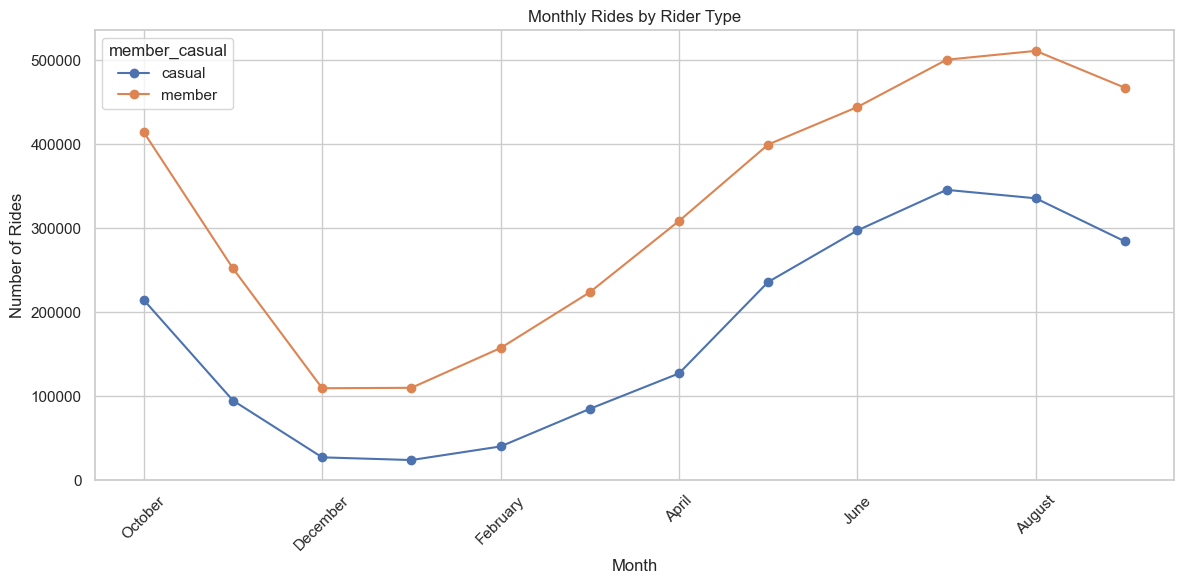

In [17]:
monthly_rides = (
    data.groupby(["ride_month_name", "member_casual"])
    .size().unstack(fill_value=0).reindex(month_order)
)
display(monthly_rides)
ax = monthly_rides.plot(kind="line", marker="o", figsize=(12, 6))
ax.set_title("Monthly Rides by Rider Type")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Rides")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "monthly_rides_by_rider_type.png", dpi=150)
plt.show()

### Weekday rides

member_casual,casual,member
ride_weekday,,
Monday,242886,543927
Tuesday,241560,627693
Wednesday,246730,631330
Thursday,263129,615031
Friday,331190,572515
Saturday,447265,497089
Sunday,337544,409265


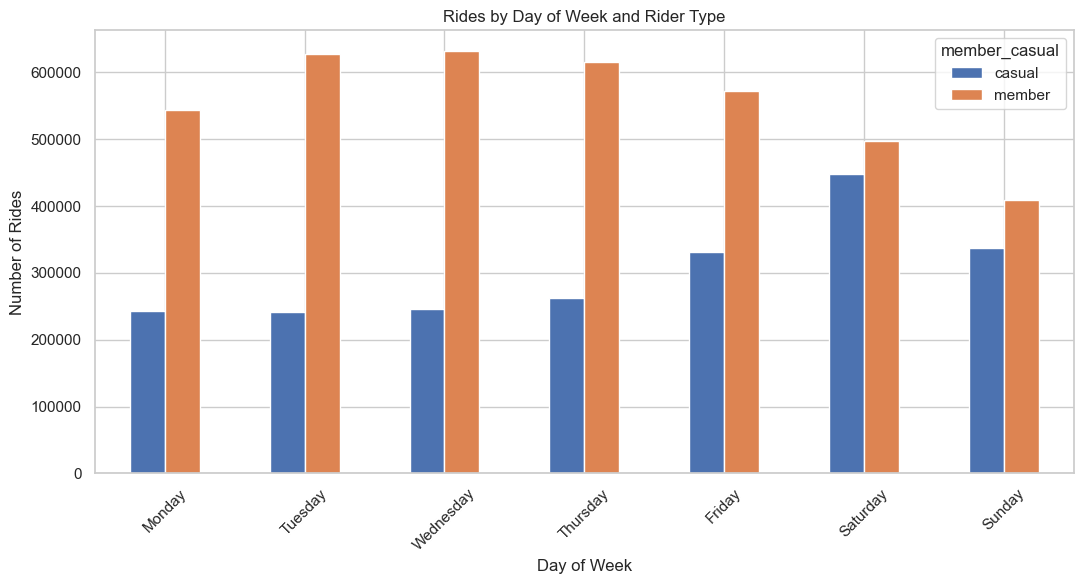

In [18]:
weekday_rides = (
    data.groupby(["ride_weekday", "member_casual"])
    .size().unstack(fill_value=0).reindex(weekday_order)
)
display(weekday_rides)
ax = weekday_rides.plot(kind="bar", figsize=(11, 6))
ax.set_title("Rides by Day of Week and Rider Type")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Number of Rides")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "weekday_rides_by_rider_type.png", dpi=150)
plt.show()

### Seasonal patterns

In [19]:
seasonal_rides = (
    data.groupby(["ride_season", "member_casual"])
    .size().unstack(fill_value=0).reindex(season_order)
)
display(seasonal_rides)
seasonal_share = seasonal_rides.div(seasonal_rides.sum(axis=0), axis=1).mul(100).round(2)
display(seasonal_share)

member_casual,casual,member
ride_season,,
Winter,91043,376476
Spring,447703,931636
Summer,978282,1455621
Autumn,593276,1133117


member_casual,casual,member
ride_season,,
Winter,4.31,9.66
Spring,21.22,23.91
Summer,46.36,37.35
Autumn,28.11,29.08


### Hourly patterns

In [20]:
hourly_rides = (
    data.groupby(["ride_hour", "member_casual"])
    .size().unstack(fill_value=0).reindex(range(24), fill_value=0)
)
display(hourly_rides)
hourly_share = hourly_rides.div(hourly_rides.sum(axis=0), axis=1).mul(100).round(2)
display(hourly_share)

member_casual,casual,member
ride_hour,,
0,46370,37010
1,30327,22562
2,19000,13195
3,11201,8710
4,8804,9744
5,14146,37925
6,29284,110362
7,52130,217458
8,74849,281662


member_casual,casual,member
ride_hour,,
0,2.20,0.95
1,1.44,0.58
2,0.90,0.34
3,0.53,0.22
4,0.42,0.25
5,0.67,0.97
6,1.39,2.83
7,2.47,5.58
8,3.55,7.23


### Ride duration

In [21]:
duration_summary = (
    data.groupby("member_casual")["ride_duration_minutes"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)
display(duration_summary)

,count,mean,median,std
member_casual,,,,
casual,2110304,18.17,11.14,35.15
member,3896850,12.17,8.69,21.32


### Bike-type preferences

In [22]:
bike_type_counts = (
    data.groupby(["member_casual", "rideable_type"])
    .size().unstack(fill_value=0)
)
bike_type_percentages = (
    bike_type_counts.div(bike_type_counts.sum(axis=1), axis=0)
    .mul(100).round(2)
)
display(bike_type_counts)
display(bike_type_percentages)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,544453,1565851
member,1234604,2662246


rideable_type,classic_bike,electric_bike
member_casual,,
casual,25.80,74.20
member,31.68,68.32


### Top starting stations

Station-level rankings exclude rides with missing station IDs or names; document this limitation in the final report.

In [23]:
top_start_stations = (
    data.dropna(subset=["start_station_id", "start_station_name"])
    .groupby(["member_casual", "start_station_name"])
    .size().reset_index(name="ride_counts")
    .sort_values(["member_casual", "ride_counts"], ascending=[True, False])
)
for rider_type in ["casual", "member"]:
    print(f"\nTop 10 starting stations — {rider_type}")
    display(top_start_stations.loc[top_start_stations["member_casual"] == rider_type].head(10))


Top 10 starting stations — casual


,member_casual,start_station_name,ride_counts
857,casual,Navy Pier,49557
343,casual,DuSable Lake Shore Dr & Monroe St,28566
804,casual,Michigan Ave & Oak St,20660
344,casual,DuSable Lake Shore Dr & North Blvd,16931
812,casual,Millennium Park,16835
1600,casual,Shedd Aquarium,16055
1713,casual,Theater on the Lake,14756
347,casual,Dusable Harbor,13629
394,casual,Field Museum,10021
17,casual,Adler Planetarium,9993



Top 10 starting stations — member


,member_casual,start_station_name,ride_counts
2025,member,Canal St & Madison St,22694
3546,member,State St & Chicago Ave,22162
2110,member,Clinton St & Jackson Blvd,19873
3644,member,Wells St & Elm St,19179
3643,member,Wells St & Concord Ln,19048
2112,member,Clinton St & Madison St,18528
2470,member,Kingsbury St & Kinzie St 2,18137
3646,member,Wells St & Hubbard St,17772
3647,member,Wells St & Huron St,17328
2117,member,Clinton St & Washington Blvd 2,17306


### Top ending stations

In [27]:
top_end_stations = (
    data.dropna(subset=["end_station_id", "end_station_name"])
    .groupby(["member_casual", "end_station_name"])
    .size().reset_index(name="ride_counts")
    .sort_values(["member_casual", "ride_counts"], ascending=[True, False])
)
for rider_type in ["casual", "member"]:
    print(f"\nTop 10 ending stations — {rider_type}")
    display(top_end_stations.loc[top_end_stations["member_casual"] == rider_type].head(10))


Top 10 ending stations — casual


,member_casual,end_station_name,ride_counts
854,casual,Navy Pier,50596
343,casual,DuSable Lake Shore Dr & Monroe St,25855
802,casual,Michigan Ave & Oak St,20939
344,casual,DuSable Lake Shore Dr & North Blvd,18590
809,casual,Millennium Park,17844
1747,casual,Theater on the Lake,16135
1635,casual,Shedd Aquarium,14352
347,casual,Dusable Harbor,11847
828,casual,Montrose Harbor,9605
1819,casual,Wells St & Concord Ln,9117



Top 10 ending stations — member


,member_casual,end_station_name,ride_counts
3588,member,State St & Chicago Ave,22659
2060,member,Canal St & Madison St,22129
3685,member,Wells St & Concord Ln,19259
2145,member,Clinton St & Jackson Blvd,19196
2147,member,Clinton St & Madison St,19070
3686,member,Wells St & Elm St,19011
2503,member,Kingsbury St & Kinzie St 2,18596
3688,member,Wells St & Hubbard St,18147
2152,member,Clinton St & Washington Blvd 2,17184
3689,member,Wells St & Huron St,16916


## Notes and limitations

- Monthly archive filenames are assumed to follow `YYYYMM-divvy-tripdata.zip`; verify the official archive if a download fails.
- The download cell retrieves the source files again each time it runs. A later reproducibility improvement could cache the ZIP files and record source URLs.
- Timestamps are parsed without imposing a new time zone to avoid silently changing the existing DST-related handling.
- Cleaning thresholds are project decisions and should be documented.
- Ride counts represent trips, not unique riders.
- Station rankings exclude rows with missing station IDs or names; missing station data may introduce bias.
- This is an improved working notebook based on the code and project details shared in the conversation, not a byte-for-byte reconstruction of every original notebook cell.
- Reconcile final Python results with MySQL and Tableau before publishing final recommendations.